### this script plots the authorship representation

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import geopandas as gp
import matplotlib.colors as colors
import numpy as np
import matplotlib.patches as mpatches
from matplotlib.lines import Line2D

In [7]:
authorship_norm_path="../../data/dropbox/LaborDivision/Data/deriveddata/authorship_shuffle/authorship_norm.pkl"
ingroup_path = '../../data/dropbox/LaborDivision/Data/additionaldata/cntry_classification/cntry_group_meta.csv'

In [60]:
authorship_norm_plot_path='../../data/dropbox/LaborDivision/figs/authorship_normed.pdf'
authorship_norm_plot_legend_path='../../data/dropbox/LaborDivision/figs/authorship_normed_legend.pdf'
authorship_norm_ann_plot_path='../../data/dropbox/LaborDivision/figs/authorship_normed_annual.pdf'

In [4]:
norm_df=pd.read_pickle(authorship_norm_path)

In [9]:
ingroup_df=pd.read_csv(ingroup_path)
ingroup_df=ingroup_df[['Code','ST']].drop_duplicates()
ingroup_df.head()

,Code,ST
0,AFG,Others
1,ALB,Lagging
2,DZA,Lagging
3,AND,Others
4,AGO,Lagging


In [10]:
norm_df.head()

,cntry,year,role,raw,shuffle
0,ABW,2014,F,1,0.30
1,ABW,2016,F,1,1.25
2,ABW,2016,M,4,2.50
3,ABW,2017,M,10,7.15
4,ABW,2018,F,1,0.85


In [11]:
alltime=norm_df.groupby(['cntry','role']).agg({'raw':'sum','shuffle':'sum'}).reset_index() #group over years

In [12]:
alltime['ratio']=alltime['raw']/alltime['shuffle']

In [13]:
alltime = alltime.pivot(index='cntry',columns='role',values='ratio')

In [14]:
alltime.head()

role,F,L,M
cntry,,,
ABW,1.008403,1.075269,1.242485
AFG,0.781906,0.627719,1.122522
AGO,0.783926,0.682432,1.105365
ALB,1.003160,0.674532,1.074146
AND,1.284404,0.728155,1.030162


In [15]:
def map_group(fratio,lratio):
    if fratio<1 and lratio<1:
        return 0.5
    elif fratio>1 and lratio<1:
        return 1.5
    elif fratio<1 and lratio>1:
        return 2.5
    elif fratio>1 and lratio>1:
        return 3.5
alltime['group']=alltime.apply(lambda x:map_group(x.F,x.L),axis=1)

In [17]:
colorsList = ['#A6A6A6', '#F4D05E', '#EA6B5F','#912855']
cmap = colors.ListedColormap(colorsList)
bounds = np.array([0, 1, 2, 3, 4])
norm = colors.BoundaryNorm(boundaries=bounds, ncolors=4)

In [18]:
world_geo=gp.read_file("../../data/dropbox/LaborDivision/Data/additionaldata/worldmap/ne_50m_admin_0_countries.shp")

In [19]:
world_geo.loc[world_geo.NAME=='France','ISO_A3']='FRA'
world_geo.loc[world_geo.NAME=='Norway','ISO_A3']='NOR'
world_geo = world_geo[['ADMIN','NAME','ISO_A3','geometry']]
world_geo=world_geo[world_geo.NAME!='Antarctica']

In [20]:
world_geo.head()

,ADMIN,NAME,ISO_A3,geometry
0,Zimbabwe,Zimbabwe,ZWE,"POLYGON ((31.28789 -22.40205, 31.19727 -22.344..."
1,Zambia,Zambia,ZMB,"POLYGON ((30.39609 -15.64307, 30.25068 -15.643..."
2,Yemen,Yemen,YEM,"MULTIPOLYGON (((53.08564 16.64839, 52.58145 16..."
3,Vietnam,Vietnam,VNM,"MULTIPOLYGON (((104.06396 10.39082, 104.08301 ..."
4,Venezuela,Venezuela,VEN,"MULTIPOLYGON (((-60.82119 9.13838, -60.94141 9..."


In [21]:
alltime=alltime.reset_index()

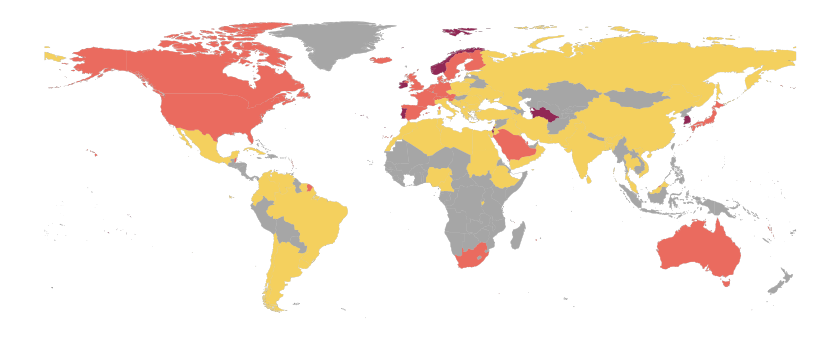

In [22]:
fig, ax=plt.subplots(figsize=(16,6))
world_geo.plot(ax = ax, linewidth=0.25, edgecolor="#8C8C8C", facecolor="#ffffff")
ax.axis("off")
df = alltime.merge(world_geo,left_on='cntry',right_on='ISO_A3')
df = gp.GeoDataFrame(df)
df.plot(column='group', cmap=cmap, norm=norm,vmin=0.9, vmax=1.1, ax=ax)
gray_patch = mpatches.Patch(color='#A6A6A6',label='Under_first;Under_last')
yellow_patch = mpatches.Patch(color='#F4D05E',label='Over_first;Under_last')
pink_patch = mpatches.Patch(color='#EA6B5F',label='Under_first;Over_last')
red_patch = mpatches.Patch(color='#912855',label='Over_first;Over_last')

plt.savefig(authorship_norm_plot_path,bbox_inches='tight')

In [33]:
role_cnt=norm_df.groupby(['cntry'])['raw'].sum().reset_index(name='count')

In [36]:
role_cnt[role_cnt.cntry.isin(alltime[alltime.group==3.5]['cntry'])]

,cntry,count
0,ABW,42
68,GIB,113
84,IRL,118530
88,ISR,173630
99,KOR,535739
105,LCA,75
118,MHL,67
136,NOR,195537
148,PRT,243069
179,TKM,62


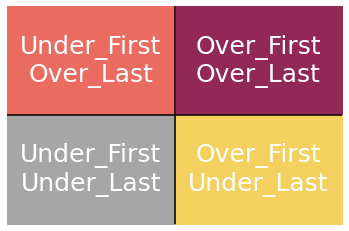

In [9]:
import matplotlib.pyplot as plt

# create a figure and axis object
fig, ax = plt.subplots()

# set the limits of the x and y axis
ax.set_xlim([-5, 5])
ax.set_ylim([-5, 5])

# draw the x and y axis
ax.axhline(y=0, color='black')
ax.axvline(x=0, color='black')

# fill the four quadrants with different colors
ax.fill_betweenx(y=[0, 5], x1=0, x2=5, color='#912855')
ax.text(2.5, 2.5, 'Over_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[0, 5], x1=-5, x2=0, color='#EA6B5F')
ax.text(-2.5, 2.5, 'Under_First\nOver_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=0, x2=5, color='#F4D05E')
ax.text(2.5, -2.5, 'Over_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.fill_betweenx(y=[-5, 0], x1=-5, x2=0, color='#A6A6A6')
ax.text(-2.5, -2.5, 'Under_First\nUnder_Last', ha='center', va='center',fontsize=25, c='white')

ax.set_xticks([])
ax.set_yticks([])

ax.spines['right'].set_visible(False)
ax.spines['top'].set_visible(False)
ax.spines['left'].set_visible(False)
ax.spines['bottom'].set_visible(False)

plt.savefig(authorship_norm_plot_legend_path,bbox_inches='tight')

In [37]:
norm_df['ratio']=norm_df['raw']/norm_df['shuffle']
norm_df['ratio']=np.log(norm_df['ratio'])

In [39]:
ingroup_df.head()

,Code,ST
0,AFG,Others
1,ALB,Lagging
2,DZA,Lagging
3,AND,Others
4,AGO,Lagging


In [40]:
norm_df=norm_df.merge(ingroup_df,left_on='cntry',right_on='Code',how='left')

In [44]:
norm_df=norm_df.replace(to_replace={'ST':{'Others':'Lagging'}})

In [46]:
norm_df.ST.unique()

array(['Lagging', 'Developing', 'Advanced', 'Proficient'], dtype=object)

In [58]:
def plot_line(data,authorship,ax,title):
    df=data[data.role==authorship]
    sns.lineplot(x='year',y='ratio',hue='ST',data=df,ax=ax,legend=False,
             hue_order=['Advanced','Proficient','Developing','Lagging'],
             palette={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'})
    ax.axhline(y=0, color='#C8C8C8', linestyle='--')
    ax.set_xlabel("")
    ax.set_ylabel("")
    ax.set_title(title,fontsize=12)
    return ax

/home/miaoli/conda/envs/funding/lib/python3.8/site-packages/numpy/lib/function_base.py:3961: RuntimeWarning: invalid value encountered in subtract
  diff_b_a = subtract(b, a)


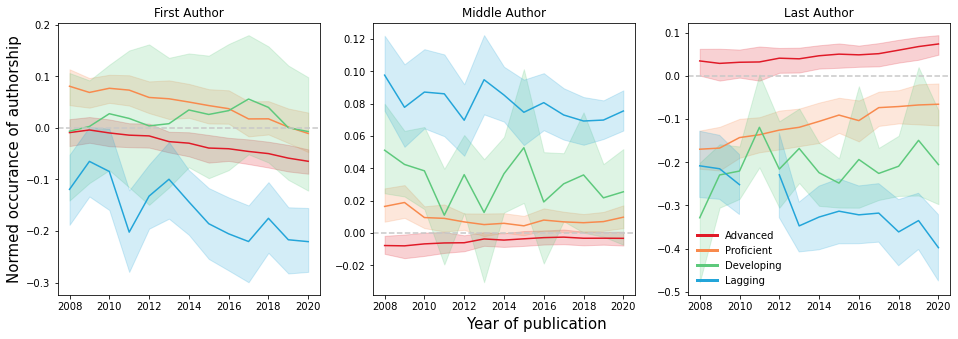

In [61]:
fig, ax=plt.subplots(nrows=1,ncols=3,figsize=(16,5))
ax0=plot_line(norm_df,'F',ax[0],'First Author')
ax0.set_ylabel("Normed occurance of authorship",fontsize=15)
ax1=plot_line(norm_df,'M',ax[1],'Middle Author')
ax2=plot_line(norm_df,'L',ax[2],'Last Author')

colors = ['#E01A27', '#F88A4D', '#5DC97C','#23A5D9']
lines = [Line2D([0], [0], color=c, linewidth=3, linestyle='-') for c in colors]
labels = ['Advanced', 'Proficient', 'Developing','Lagging']
plt.legend(lines, labels, frameon=False)
fig.text(x=0.48,y=0.03,s="Year of publication",fontsize=15)
plt.savefig(authorship_norm_ann_plot_path,bbox_inches='tight')